# Customer churn with PySpark MLlib

A reference machine-learning pipeline for Spark and Databricks, trained on real data: IBM's [Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d) sample, with 7,043 customers of a telephone and internet company. For each customer it records 19 attributes and whether they left in the last month (`Churn`).

The notebook runs on a local Spark session; on Databricks the existing `spark` session is used and the code is the same. All functions come from `src/churn_pipeline.py`.

In [1]:
import os, sys
from pathlib import Path

os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
sys.path.insert(0, str(Path("src").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession, functions as F
import churn_pipeline as cp

spark = (SparkSession.builder.master("local[*]").appName("CustomerChurnPipeline")
         .config("spark.ui.enabled", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Spark 3.5.9


## 1. Data

In [2]:
customers = cp.load_customers(spark, str(cp.download_data(Path("data")))).cache()
n = customers.count()
rate = customers.agg(F.avg("label")).first()[0]
print(f"{n} customers, {len(cp.NUMERIC) + len(cp.CATEGORICAL)} attributes, churn rate {rate:.1%}")
customers.select("customerID", "tenure", "Contract", "InternetService", "MonthlyCharges", "Churn").limit(5).toPandas()

7043 customers, 19 attributes, churn rate 26.5%


,customerID,tenure,Contract,InternetService,MonthlyCharges,Churn
0,7590-VHVEG,1.0,Month-to-month,DSL,29.85,No
1,5575-GNVDE,34.0,One year,DSL,56.95,No
2,3668-QPYBK,2.0,Month-to-month,DSL,53.85,Yes
3,7795-CFOCW,45.0,One year,DSL,42.30,No
4,9237-HQITU,2.0,Month-to-month,Fiber optic,70.70,Yes


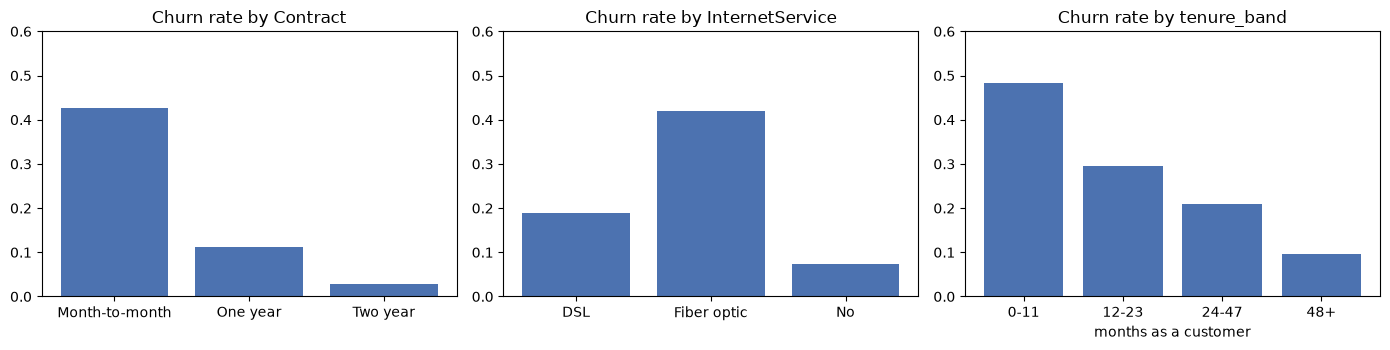

In [3]:
def churn_by(col):
    return customers.groupBy(col).agg(F.avg("label").alias("churn"), F.count("*").alias("n")).orderBy(col).toPandas()

tenure_band = customers.withColumn(
    "tenure_band", F.when(F.col("tenure") < 12, "0-11").when(F.col("tenure") < 24, "12-23")
    .when(F.col("tenure") < 48, "24-47").otherwise("48+"))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, df in [(axes[0], "Contract", churn_by("Contract")),
                    (axes[1], "InternetService", churn_by("InternetService")),
                    (axes[2], "tenure_band", tenure_band.groupBy("tenure_band").agg(F.avg("label").alias("churn"))
                                              .orderBy("tenure_band").toPandas())]:
    ax.bar(df[col], df["churn"], color="#4c72b0")
    ax.set_ylim(0, 0.6)
    ax.set_title(f"Churn rate by {col}")
axes[2].set_xlabel("months as a customer")
plt.tight_layout()

Month-to-month contracts churn far more than one- or two-year contracts. Fiber-optic customers churn more than DSL customers, and customers who joined recently churn far more than long-standing ones. A model should find the same signals.

## 2. Why the previous version measured nothing

The previous version trained on 20 invented rows and kept a random 25% for testing. It also turned the country into a single number (`StringIndexer`), so the logistic regression treated "Mexico" as if it were twice "Chile".

In [4]:
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import StringIndexer, VectorAssembler

rows = [(1, "mujer", 25, 32000, "Espana", 0), (2, "hombre", 45, 57000, "Mexico", 1), (3, "mujer", 31, 43000, "Espana", 0),
        (4, "hombre", 29, 25000, "Chile", 0), (5, "mujer", 38, 72000, "Mexico", 1), (6, "hombre", 35, 50000, "Argentina", 0),
        (7, "mujer", 22, 28000, "Chile", 1), (8, "hombre", 39, 61000, "Espana", 0), (9, "mujer", 33, 46000, "Mexico", 1),
        (10, "hombre", 28, 34000, "Argentina", 0), (11, "mujer", 51, 83000, "Mexico", 1), (12, "hombre", 41, 69000, "Chile", 1),
        (13, "mujer", 27, 37000, "Argentina", 0), (14, "hombre", 48, 76000, "Espana", 1), (15, "mujer", 36, 52000, "Chile", 0),
        (16, "hombre", 24, 29000, "Mexico", 0), (17, "mujer", 44, 65000, "Argentina", 1), (18, "hombre", 32, 41000, "Espana", 0),
        (19, "mujer", 55, 91000, "Mexico", 1), (20, "hombre", 30, 39000, "Chile", 0)]
toy = spark.createDataFrame(rows, ["id_cliente", "genero", "edad", "ingresos", "pais", "churn"])
toy_train, toy_test = toy.randomSplit([0.75, 0.25], seed=42)
old = Pipeline(stages=[
    StringIndexer(inputCol="genero", outputCol="genero_idx", handleInvalid="keep"),
    StringIndexer(inputCol="pais", outputCol="pais_idx", handleInvalid="keep"),
    VectorAssembler(inputCols=["genero_idx", "pais_idx", "edad", "ingresos"], outputCol="features"),
    LogisticRegression(featuresCol="features", labelCol="churn", maxIter=30),
]).fit(toy_train)
toy_auc = BinaryClassificationEvaluator(labelCol="churn").evaluate(old.transform(toy_test))
print(f"test rows: {toy_test.count()}, of which churners: {toy_test.filter('churn = 1').count()}, AUC: {toy_auc:.3f}")

test rows: 8, of which churners: 4, AUC: 0.750


An AUC computed on a handful of rows can land anywhere between 0 and 1 by chance; it says nothing about the model.

## 3. The pipeline

- Each categorical attribute goes through `StringIndexer` and `OneHotEncoder`, so categories with no natural order (payment method, contract type) are not treated as numbers.
- `tenure`, `MonthlyCharges` and `TotalCharges` are assembled and standardised.
- `TotalCharges` is blank for 11 customers with tenure 0 (they have not been billed yet) and is set to 0.
- Three models are compared: logistic regression, random forest and gradient-boosted trees. Each is tuned with 3-fold cross-validation on the training set (80% of customers).
- The best model is chosen by its cross-validated AUC, and only then measured on the test set (the other 20%).

In [5]:
train, test = customers.randomSplit([0.8, 0.2], seed=cp.SEED)
train = train.cache()
print(f"train: {train.count()} customers, test: {test.count()} customers")

rows, models = [], {}
for name, (pipeline, grid) in cp.candidate_pipelines().items():
    model, cv_auc = cp.fit_with_cv(pipeline, grid, train)
    models[name] = model
    rows.append({"model": name, "cv_auc_roc": cv_auc, **cp.evaluate(model.transform(test))})
results = pd.DataFrame(rows).set_index("model")
results.round(3)

train: 5698 customers, test: 1345 customers


,cv_auc_roc,auc_roc,auc_pr,accuracy,precision,recall,churners_in_top_20pct
model,,,,,,,
Logistic regression,0.847,0.843,0.658,0.809,0.692,0.547,0.518
Random forest,0.843,0.838,0.662,0.787,0.695,0.401,0.488
Gradient-boosted trees,0.846,0.843,0.677,0.799,0.674,0.515,0.499


`cv_auc_roc` is measured on the training set by cross-validation; every other column is measured on the test set. `churners_in_top_20pct` is the share of all test-set churners found among the 20% of customers the model rates as most at risk.

The three models are practically tied: the differences in AUC are under half a point, and the logistic regression wins on cross-validation. On this dataset, simple linear effects (contract type, tenure, charges) explain most of what can be predicted, and a linear model has the advantage of being readable.

## 4. Using the scores

Contacting the riskiest 20% reaches 52% of churners (2.6 times a random selection).


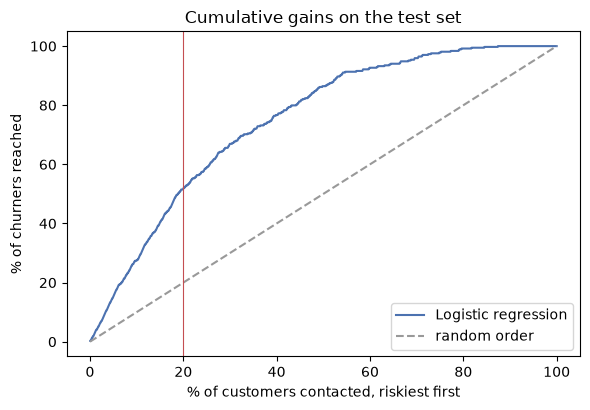

In [6]:
best_name = results["cv_auc_roc"].idxmax()
best = models[best_name]
scored = cp.churn_score(best.transform(test)).select("label", "churn_probability").toPandas()
scored = scored.sort_values("churn_probability", ascending=False).reset_index(drop=True)
contacted = np.arange(1, len(scored) + 1) / len(scored)
captured = scored["label"].cumsum() / scored["label"].sum()

plt.figure(figsize=(6, 4.2))
plt.plot(contacted * 100, captured * 100, color="#4c72b0", label=best_name)
plt.plot([0, 100], [0, 100], color="#999999", linestyle="--", label="random order")
plt.axvline(20, color="#c44e52", linewidth=0.8)
plt.xlabel("% of customers contacted, riskiest first")
plt.ylabel("% of churners reached")
plt.title("Cumulative gains on the test set")
plt.legend()
plt.tight_layout()
top20 = captured[contacted <= 0.2].iloc[-1]
print(f"Contacting the riskiest 20% reaches {top20:.0%} of churners ({top20 / 0.2:.1f} times a random selection).")

This is how a churn model is usually used: a retention team cannot call every customer, so it calls the riskiest ones first.

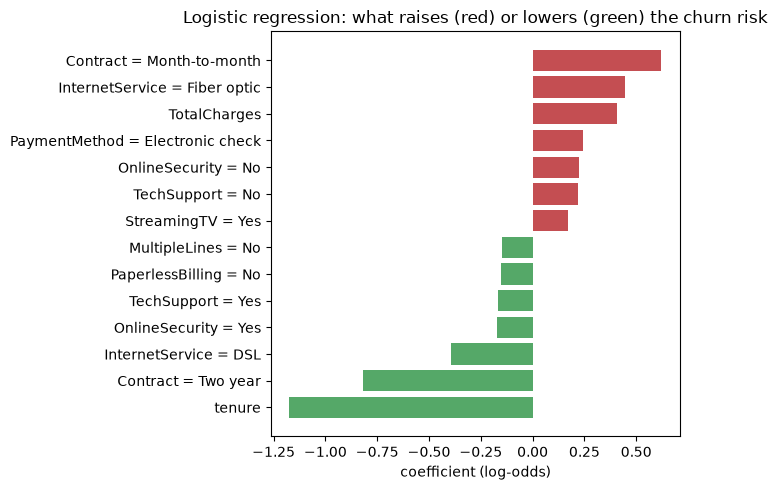

In [7]:
lr_model = best.stages[-1]
attrs = best.transform(test.limit(1)).schema["features"].metadata["ml_attr"]["attrs"]
names = {a["idx"]: a["name"] for group in attrs.values() for a in group}
coef = pd.Series(lr_model.coefficients.toArray(), index=[names[i] for i in range(len(names))])
numeric_names = {f"numeric_scaled_{i}": c for i, c in enumerate(cp.NUMERIC)}
numeric_names.update({str(i): c for i, c in enumerate(cp.NUMERIC)})
coef.index = [numeric_names.get(c, c).replace("_ohe_", " = ") for c in coef.index]
top = pd.concat([coef.sort_values().head(7), coef.sort_values().tail(7)])

plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values, color=["#55a868" if v < 0 else "#c44e52" for v in top.values])
plt.title("Logistic regression: what raises (red) or lowers (green) the churn risk")
plt.xlabel("coefficient (log-odds)")
plt.tight_layout()

The coefficients are measured against each category's reference level, and the numeric ones are per standard deviation, so they show direction and relative weight rather than effects that can be read in isolation. The pattern matches the exploration: a long contract and a long tenure lower the risk; fiber-optic service, electronic-check payment and month-to-month contracts raise it.

## 5. Exporting predictions and the model

In [8]:
cp.predictions_for_export(best.transform(test)).printSchema()

root
 |-- customerID: string (nullable = true)
 |-- label: double (nullable = true)
 |-- prediction: double (nullable = false)
 |-- churn_probability: double (nullable = true)



The export contains only plain columns, so it can be written as CSV. (The previous version tried to write the `probability` vector, which the CSV writer rejects.) `src/churn_pipeline.py --predictions-output <folder> --model-output <folder>` writes both; on Databricks the paths can be Unity Catalog volumes. On Windows without Hadoop's `winutils.exe` Spark cannot write local files; on Linux, macOS and Databricks it works as is.

In [9]:
spark.stop()